In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("online_retail_II.csv", encoding="latin-1")

print(df.shape)
print(df.columns.tolist())
df.head()


(1067371, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
# 1. make sure Invoice is text, and dates are real dates
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# 2. remove rows with no customer
df = df.dropna(subset=["Customer ID"])
df["Customer ID"] = df["Customer ID"].astype(int)

# 3. remove cancelled orders (Invoice starts with 'C')
df = df[~df["Invoice"].str.startswith("C")]

# 4. remove bad quantities and prices
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

# 5. remove non-product codes (postage, fees, etc.)
non_products = ["POST", "D", "M", "BANK CHARGES", "PADS", "DOT", "CRUK", "AMAZONFEE", "B"]
df = df[~df["StockCode"].isin(non_products)]

# 6. clean the description text
df["Description"] = df["Description"].astype(str).str.strip()

df = df.reset_index(drop=True)

print("Rows after cleaning:", df.shape[0])
print("Unique customers:", df["Customer ID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Rows after cleaning: 802932
Unique customers: 5862
Unique products: 4625
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [3]:
from scipy.sparse import csr_matrix

#  1. time split: last 3 months = test 
cutoff = pd.Timestamp("2011-09-09")
train = df[df["InvoiceDate"] < cutoff]
test = df[df["InvoiceDate"] >= cutoff]

#  2. keep only products bought by 5+ customers, customers with 5+ products 
prod_counts = train.groupby("StockCode")["Customer ID"].nunique()
good_products = prod_counts[prod_counts >= 5].index
train = train[train["StockCode"].isin(good_products)]

cust_counts = train.groupby("Customer ID")["StockCode"].nunique()
good_customers = cust_counts[cust_counts >= 5].index
train = train[train["Customer ID"].isin(good_customers)]

# test only keeps customers and products that exist in train
test = test[test["Customer ID"].isin(good_customers) & test["StockCode"].isin(good_products)]

# 3. build the matrix
cust_ids = np.sort(train["Customer ID"].unique())
prod_ids = np.sort(train["StockCode"].unique())
cust_index = {c: i for i, c in enumerate(cust_ids)}
prod_index = {p: i for i, p in enumerate(prod_ids)}

agg = train.groupby(["Customer ID", "StockCode"])["Quantity"].sum().reset_index()
rows = agg["Customer ID"].map(cust_index)
cols = agg["StockCode"].map(prod_index)
vals = np.log1p(agg["Quantity"])

A = csr_matrix((vals, (rows, cols)), shape=(len(cust_ids), len(prod_ids)))

# product names for later (so we can read recommendations)
product_names = df.groupby("StockCode")["Description"].agg(lambda x: x.mode()[0])

#  4. summary 
sparsity = 1 - A.nnz / (A.shape[0] * A.shape[1])
print("Matrix shape (customers x products):", A.shape)
print("Non-zero cells:", A.nnz)
print("Sparsity: {:.1%}".format(sparsity))
print("Train rows:", len(train), "| Test rows:", len(test))
print("Customers in test:", test["Customer ID"].nunique())

Matrix shape (customers x products): (4962, 3973)
Non-zero cells: 389524
Sparsity: 98.0%
Train rows: 638582 | Test rows: 122624
Customers in test: 2244


In [4]:
from sklearn.metrics.pairwise import cosine_similarity

#  ground truth: what each customer bought in the test period 
test_agg = test[["Customer ID", "StockCode"]].drop_duplicates()
test_items = {}
for c, p in zip(test_agg["Customer ID"], test_agg["StockCode"]):
    test_items.setdefault(cust_index[c], set()).add(prod_index[p])

#  evaluation function (we will reuse this for SVD) 
def evaluate(score_matrix, K=10):
    scores = np.array(score_matrix, dtype=np.float32)   # copy
    r, c = A.nonzero()
    scores[r, c] = -np.inf          # don't recommend what they already bought
    recalls, ndcgs = [], []
    for u, truth in test_items.items():
        top = np.argpartition(-scores[u], K)[:K]
        top = top[np.argsort(-scores[u][top])]
        hits = np.array([1 if i in truth else 0 for i in top])
        recalls.append(hits.sum() / len(truth))
        dcg = (hits / np.log2(np.arange(2, K + 2))).sum()
        idcg = (1 / np.log2(np.arange(2, min(len(truth), K) + 2))).sum()
        ndcgs.append(dcg / idcg)
    return np.mean(recalls), np.mean(ndcgs)

results = {}

#  baseline 1: popularity 
popularity = np.asarray((A > 0).sum(axis=0)).ravel()
pop_scores = np.tile(popularity, (A.shape[0], 1))
results["Popularity"] = evaluate(pop_scores)

#  baseline 2: item-item cosine similarity 
S = cosine_similarity(A.T)          # product x product similarity
np.fill_diagonal(S, 0)
item_scores = A @ S                 # customer x product scores
results["Item-Item CF"] = evaluate(item_scores)

#  show results 
res_df = pd.DataFrame(results, index=["Recall@10", "NDCG@10"]).T
print(res_df.round(4))

              Recall@10  NDCG@10
Popularity       0.0125   0.0423
Item-Item CF     0.0199   0.0664


k= 10 | Recall@10=0.0164 | NDCG@10=0.0592 | variance explained=19.7%
k= 20 | Recall@10=0.0201 | NDCG@10=0.0693 | variance explained=25.2%
k= 50 | Recall@10=0.0214 | NDCG@10=0.0743 | variance explained=34.9%
k=100 | Recall@10=0.0226 | NDCG@10=0.0741 | variance explained=45.0%


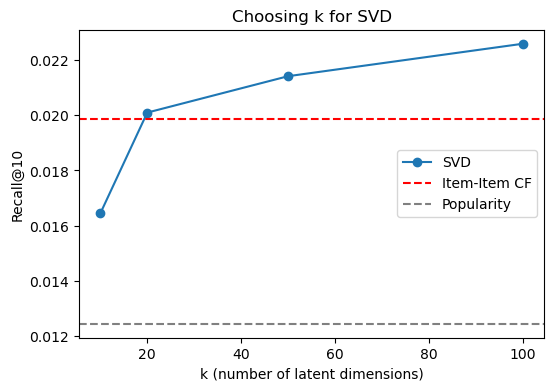

In [5]:
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

k_values = [10, 20, 50, 100]
svd_results = {}
models = {}

for k in k_values:
    svd = TruncatedSVD(n_components=k, random_state=42)
    Z = svd.fit_transform(A)            # customer embeddings (U x Sigma)
    scores = Z @ svd.components_        # predicted score for every customer x product
    recall, ndcg = evaluate(scores)
    svd_results[k] = (recall, ndcg)
    models[k] = (svd, Z)
    print(f"k={k:3d} | Recall@10={recall:.4f} | NDCG@10={ndcg:.4f} | variance explained={svd.explained_variance_ratio_.sum():.1%}")

# plot k vs Recall@10
plt.figure(figsize=(6, 4))
plt.plot(k_values, [svd_results[k][0] for k in k_values], marker="o", label="SVD")
plt.axhline(results["Item-Item CF"][0], color="red", linestyle="--", label="Item-Item CF")
plt.axhline(results["Popularity"][0], color="gray", linestyle="--", label="Popularity")
plt.xlabel("k (number of latent dimensions)")
plt.ylabel("Recall@10")
plt.title("Choosing k for SVD")
plt.legend()
plt.show()


In [6]:
from sklearn.neighbors import NearestNeighbors
import networkx as nx

# ---- 1. use the k=50 customer embeddings ----
svd50, Z50 = models[50]

# ---- 2. connect each customer to 10 most similar customers ----
nn = NearestNeighbors(n_neighbors=11, metric="cosine").fit(Z50)
dist, nbrs = nn.kneighbors(Z50)

G = nx.Graph()
G.add_nodes_from(range(len(cust_ids)))
for i in range(len(cust_ids)):
    for d, j in zip(dist[i][1:], nbrs[i][1:]):     # [1:] skips the customer itself
        G.add_edge(i, int(j), weight=float(1 - d))

print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

# ---- 3. community detection (Louvain) ----
communities = nx.community.louvain_communities(G, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
mod = nx.community.modularity(G, communities, weight="weight")
print("Communities found:", len(communities))
print("Modularity:", round(mod, 3))
print("Community sizes:", [len(c) for c in communities])

# ---- 4. save the community of each customer ----
comm_of = {}
for cid, members in enumerate(communities):
    for m in members:
        comm_of[m] = cid
cust_df = pd.DataFrame({"Customer ID": cust_ids,
                        "community": [comm_of[i] for i in range(len(cust_ids))]})

# ---- 5. describe each community by its most characteristic products ----
B = (A > 0).astype(float).tocsr()
overall = np.asarray(B.mean(axis=0)).ravel()

for cid, members in enumerate(communities[:6]):          # top 6 biggest communities
    idx = list(members)
    comm_mean = np.asarray(B[idx].mean(axis=0)).ravel()
    top = np.argsort(-(comm_mean - overall))[:5]
    print(f"\nCommunity {cid} ({len(idx)} customers) - typical products:")
    for t in top:
        print("   -", product_names.get(prod_ids[t], prod_ids[t]))

cust_df.to_csv("customer_communities.csv", index=False)

Nodes: 4962 | Edges: 37611
Communities found: 21
Modularity: 0.695
Community sizes: [618, 512, 506, 388, 334, 300, 262, 225, 213, 210, 199, 177, 155, 154, 145, 122, 108, 101, 84, 82, 67]

Community 0 (618 customers) - typical products:
   - JUMBO BAG RED RETROSPOT
   - JUMBO BAG PINK POLKADOT
   - JUMBO BAG STRAWBERRY
   - LUNCH BAG RED RETROSPOT
   - JUMBO STORAGE BAG SUKI

Community 1 (512 customers) - typical products:
   - SPACEBOY BIRTHDAY CARD
   - SWALLOWS GREETING CARD
   - RED RETROSPOT WRAP
   - TEA PARTY BIRTHDAY CARD
   - COWBOYS AND INDIANS BIRTHDAY CARD

Community 2 (506 customers) - typical products:
   - ASSORTED COLOUR BIRD ORNAMENT
   - HEART OF WICKER SMALL
   - PAINTED METAL PEARS ASSORTED
   - HEART OF WICKER LARGE
   - WHITE HANGING HEART T-LIGHT HOLDER

Community 3 (388 customers) - typical products:
   - ANTIQUE SILVER TEA GLASS ETCHED
   - HANGING HEART ZINC T-LIGHT HOLDER
   - SINGLE HEART ZINC T-LIGHT HOLDER
   - ANTIQUE SILVER TEA GLASS ENGRAVED
   - HANGING

In [7]:
# ---- 1. RFM from training data only ----
train = train.copy()
train["Revenue"] = train["Quantity"] * train["Price"]

rfm = train.groupby("Customer ID").agg(
    last_purchase=("InvoiceDate", "max"),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum")
).reindex(cust_ids)
rfm["recency_days"] = (cutoff - rfm["last_purchase"]).dt.days

# ---- 2. top-3 SVD recommendations per customer ----
scores = Z50 @ svd50.components_
r, c = A.nonzero()
scores[r, c] = -np.inf                       # skip products already bought
top3 = np.argsort(-scores, axis=1)[:, :3]

def pname(j):
    return product_names.get(prod_ids[j], prod_ids[j])

# ---- 3. segment names ----
seg_names = {0: "Bag buyers", 1: "Cards & wrap buyers", 2: "Home decor buyers",
             3: "T-light & tea glass buyers", 4: "Baking buyers", 5: "Vintage games buyers"}

nba = pd.DataFrame({
    "Customer ID": cust_ids,
    "community": [comm_of[i] for i in range(len(cust_ids))],
    "recency_days": rfm["recency_days"].values,
    "frequency": rfm["frequency"].values,
    "monetary": rfm["monetary"].values,
    "rec_1": [pname(top3[i, 0]) for i in range(len(cust_ids))],
    "rec_2": [pname(top3[i, 1]) for i in range(len(cust_ids))],
    "rec_3": [pname(top3[i, 2]) for i in range(len(cust_ids))],
})
nba["segment"] = nba["community"].map(lambda x: seg_names.get(x, f"Community {x}"))

# ---- 4. NBA rules ----
high_value = nba["monetary"] >= nba["monetary"].quantile(0.80)

conditions = [
    nba["recency_days"] > 180,                       # gone quiet
    high_value & (nba["recency_days"] <= 90),        # big spender, still active
    nba["frequency"] <= 2,                           # new / low engagement
]
actions = ["Retention offer", "Loyalty / VIP offer", "Targeted promotion"]
nba["action"] = np.select(conditions, actions, default="Cross-sell top recommendation")

# ---- 5. results ----
print(nba["action"].value_counts())
print()
print(pd.crosstab(nba["segment"], nba["action"]).head(8))
print()
print(nba[["Customer ID", "segment", "recency_days", "frequency", "monetary", "action", "rec_1"]].head(8))

nba.to_csv("nba_output.csv", index=False)

action
Retention offer                  2275
Cross-sell top recommendation    1242
Loyalty / VIP offer               746
Targeted promotion                699
Name: count, dtype: int64

action               Cross-sell top recommendation  Loyalty / VIP offer  \
segment                                                                   
Bag buyers                                     180                  200   
Baking buyers                                   88                   53   
Cards & wrap buyers                            143                  106   
Community 10                                    49                   58   
Community 11                                    36                    9   
Community 12                                    37                   13   
Community 13                                    18                    6   
Community 14                                    45                   32   

action               Retention offer  Targeted promotion  
segm

In [8]:
# ---- 1. validation on the hidden test period ----
returned = {cust_ids[u] for u in test_items}
nba["returned_in_test"] = nba["Customer ID"].isin(returned)

print("Share of customers who bought again in the test period, by action:")
print(nba.groupby("action")["returned_in_test"].mean().round(3))

# top-3 recommendation hit rate vs popularity top-3
hit_svd = np.mean([len(set(top3[u]) & truth) > 0 for u, truth in test_items.items()])
pop3 = set(np.argsort(-popularity)[:3])
hit_pop = np.mean([len(pop3 & truth) > 0 for u, truth in test_items.items()])
print(f"\nTop-3 hit rate -> SVD: {hit_svd:.3f} | Popularity: {hit_pop:.3f}")

# ---- 2. typical products for the remaining communities ----
for cid in range(6, len(communities)):
    idx = list(communities[cid])
    comm_mean = np.asarray(B[idx].mean(axis=0)).ravel()
    top = np.argsort(-(comm_mean - overall))[:3]
    names = " | ".join(str(product_names.get(prod_ids[t], prod_ids[t])) for t in top)
    print(f"Community {cid} ({len(idx)}): {names}")

Share of customers who bought again in the test period, by action:
action
Cross-sell top recommendation    0.605
Loyalty / VIP offer              0.869
Retention offer                  0.241
Targeted promotion               0.422
Name: returned_in_test, dtype: float64

Top-3 hit rate -> SVD: 0.204 | Popularity: 0.302
Community 6 (262): HAND OVER THE CHOCOLATE   SIGN | PLEASE ONE PERSON METAL SIGN | GIN + TONIC DIET METAL SIGN
Community 7 (225): BLUE  SPOTTY CUP | PINK  SPOTTY PLATE | BLUE POLKADOT PLATE
Community 8 (213): WHITE HANGING HEART T-LIGHT HOLDER | RED HANGING HEART T-LIGHT HOLDER | WOODEN FRAME ANTIQUE WHITE
Community 9 (210): STRAWBERRY CERAMIC TRINKET BOX | SWEETHEART CERAMIC TRINKET BOX | CERAMIC STRAWBERRY CAKE MONEY BANK
Community 10 (199): PLASTERS IN TIN SPACEBOY | ROUND SNACK BOXES SET OF4 WOODLAND | PLASTERS IN TIN CIRCUS PARADE
Community 11 (177): GINGHAM HEART DECORATION | CHRISTMAS GINGHAM STAR | CHRISTMAS GINGHAM TREE
Community 12 (155): FELTCRAFT 6 FLOWER FRIEN

In [9]:
# ---- 1. name all 21 segments ----
seg_names.update({
    6: "Novelty sign buyers", 7: "Spotty tableware buyers", 8: "Hanging heart & frame decor buyers",
    9: "Ceramic trinket box buyers", 10: "Plasters tin & snack box buyers",
    11: "Christmas gingham decor buyers", 12: "Felt craft buyers",
    13: "Hot water bottle & candle buyers", 14: "Regency teaware buyers",
    15: "Fan & parasol accessory buyers", 16: "Tissue pack buyers",
    17: "Doormat buyers", 18: "Ceramic drawer knob buyers",
    19: "Lunch bag buyers", 20: "Retrospot kitchenware buyers"
})
nba["segment"] = nba["community"].map(seg_names)
nba.to_csv("nba_output.csv", index=False)

# ---- 2. fair top-3 comparison: popularity ALSO excludes already-bought items ----
pop_scores_ex = np.tile(popularity.astype(float), (A.shape[0], 1))
pop_scores_ex[r, c] = -np.inf
pop3_fair = np.argsort(-pop_scores_ex, axis=1)[:, :3]

hit_pop_fair = np.mean([len(set(pop3_fair[u]) & truth) > 0 for u, truth in test_items.items()])
print(f"Top-3 hit rate (fair) -> SVD: {hit_svd:.3f} | Popularity: {hit_pop_fair:.3f}")
print(nba["segment"].value_counts().head(8))

Top-3 hit rate (fair) -> SVD: 0.204 | Popularity: 0.124
segment
Bag buyers                    618
Cards & wrap buyers           512
Home decor buyers             506
T-light & tea glass buyers    388
Baking buyers                 334
Vintage games buyers          300
Novelty sign buyers           262
Spotty tableware buyers       225
Name: count, dtype: int64


In [10]:
from sklearn.metrics.pairwise import cosine_similarity

# 1. model results table
rows = [("Popularity", *results["Popularity"]), ("Item-Item CF", *results["Item-Item CF"])]
for k in k_values:
    rows.append((f"SVD k={k}", *svd_results[k]))
pd.DataFrame(rows, columns=["model", "recall_at_10", "ndcg_at_10"]).to_csv("model_results.csv", index=False)

# 2. related products, from the SVD product embeddings
P = svd50.components_.T
PS = cosine_similarity(P)
np.fill_diagonal(PS, -1)
out = []
for j in range(len(prod_ids)):
    for n in np.argsort(-PS[j])[:5]:
        out.append((pname(j), pname(n), round(float(PS[j, n]), 3)))
pd.DataFrame(out, columns=["product", "related_product", "similarity"]).to_csv("product_neighbors.csv", index=False)

# 3. typical products per segment
seg_rows = []
for cid, members in enumerate(communities):
    idx = list(members)
    cm = np.asarray(B[idx].mean(axis=0)).ravel()
    for t in np.argsort(-(cm - overall))[:5]:
        seg_rows.append((seg_names.get(cid, f"Community {cid}"), pname(t)))
pd.DataFrame(seg_rows, columns=["segment", "typical_product"]).to_csv("segment_products.csv", index=False)

print("saved")


saved


In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(page_title="Customer Intelligence Dashboard", layout="wide")

@st.cache_data
def load():
    return (pd.read_csv("nba_output.csv"), pd.read_csv("product_neighbors.csv"),
            pd.read_csv("segment_products.csv"), pd.read_csv("model_results.csv"))

nba, neigh, segprod, models = load()

st.title("SVD-Based Customer Intelligence & Next-Best-Action")
page = st.sidebar.radio("Page", ["Overview", "Customer analytics", "Product analytics", "Recommendations & actions"])

if page == "Overview":
    c1, c2, c3 = st.columns(3)
    c1.metric("Customers", f"{len(nba):,}")
    c2.metric("Segments", nba["segment"].nunique())
    c3.metric("Total spend (training period)", f"£{nba['monetary'].sum():,.0f}")
    st.subheader("Model comparison (hidden 3-month test set)")
    st.dataframe(models.round(4))
    st.bar_chart(models.set_index("model")[["recall_at_10", "ndcg_at_10"]])
    st.subheader("Recommended actions")
    st.bar_chart(nba["action"].value_counts())

elif page == "Customer analytics":
    st.subheader("Customer segments (graph communities)")
    st.bar_chart(nba["segment"].value_counts())
    summary = nba.groupby("segment").agg(
        customers=("Customer ID", "count"), avg_spend=("monetary", "mean"),
        avg_orders=("frequency", "mean"), avg_recency_days=("recency_days", "mean")
    ).round(1).sort_values("customers", ascending=False)
    st.dataframe(summary)
    seg = st.selectbox("Inspect a segment", summary.index)
    st.write("**Typical products:**", ", ".join(segprod[segprod["segment"] == seg]["typical_product"].astype(str)))
    top = nba[nba["segment"] == seg].sort_values("monetary", ascending=False).head(10)
    st.write("**Highest-value customers in this segment**")
    st.dataframe(top[["Customer ID", "monetary", "frequency", "recency_days", "action"]])

elif page == "Product analytics":
    st.subheader("Related products (from SVD product embeddings)")
    prod = st.selectbox("Choose a product", sorted(neigh["product"].astype(str).unique()))
    st.dataframe(neigh[neigh["product"].astype(str) == prod][["related_product", "similarity"]])

else:
    st.subheader("Customer lookup")
    cid = st.selectbox("Customer ID", nba["Customer ID"])
    row = nba[nba["Customer ID"] == cid].iloc[0]
    st.write(f"**Segment:** {row['segment']}  |  **Next-best-action:** {row['action']}")
    st.write(f"Recency: {row['recency_days']} days | Orders: {row['frequency']} | Spend: £{row['monetary']:,.0f}")
    st.write("**Recommended products:**", row["rec_1"], "/", row["rec_2"], "/", row["rec_3"])
    st.subheader("Action list")
    pick = st.selectbox("Filter by action", ["All"] + sorted(nba["action"].unique()))
    view = nba if pick == "All" else nba[nba["action"] == pick]
    st.dataframe(view[["Customer ID", "segment", "action", "rec_1", "rec_2", "rec_3"]])

Overwriting app.py
